# Sleep Staging — Exploración Inicial del Dataset

**Objetivo:** Entender la estructura del dataset antes de cualquier preprocesamiento o modelado.

**Librería principal:** MNE-Python, ampliamente utilizada para el análisis de señales neurofisiológicas. 

**Formato de datos:** EDF (European Data Format), utilizado habitualmente para almacenar señales biomédicas.

---
> **Preguntas a responder:**  
> - ¿Cuántos sujetos y cuántos archivos hay?  
> - ¿Todos los archivos tienen los mismos canales y sampling rate?  
> - ¿Las clases están balanceadas?  
> - ¿Hay archivos corruptos o problemáticos?

## 0. Configuración e importaciones

In [67]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from matplotlib.patches import Patch
from scipy.signal import welch, spectrogram

# Reducir mensajes informativos y warnings de MNE
mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_PATH = "../data/recordings"
LABELS_PATH = "../data/recordings"

# ============================================================
# Parámetros generales
# ============================================================

EPOCH_DURATION_S = 30
SECONDS_PER_HOUR = 3600
EPOCH_DURATION_H = EPOCH_DURATION_S / SECONDS_PER_HOUR

SHORT_RECORDING_THRESHOLD_H = 4.0
AMPLITUDE_THRESHOLD_UV = 500
FLAT_DURATION_S = 1.0
REVIEW_THRESHOLD_PCT = 70

STAGE_ORDER = [
    "Sleep stage W",
    "Sleep stage R",
    "Sleep stage N1",
    "Sleep stage N2",
    "Sleep stage N3"
]

STAGE_TO_Y = {
    stage: i
    for i, stage in enumerate(STAGE_ORDER)
}

STAGE_COLORS = {
    "Sleep stage W": "#e74c3c",
    "Sleep stage N1": "#f39c12",
    "Sleep stage N2": "#3498db",
    "Sleep stage N3": "#2c3e50",
    "Sleep stage R": "#27ae60",
}

FREQ_BANDS = {
    "Delta": (0.5, 4),
    "Theta": (4, 8),
    "Alpha": (8, 12),
    "Sigma": (12, 15),
    "Beta": (15, 30)
}

print("MNE version:", mne.__version__)

MNE version: 1.12.1


---
## 1. Inventario de archivos
 
En este punto, se separan archivos EDF de señales vs. archivos de anotaciones (`_sleepscoring.txt`).

In [68]:
all_files = sorted(os.listdir(DATA_PATH))

# Separar señales de anotaciones
edf_signals = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' not in f]   # contiene las señales
edf_annots  = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' in f]       # contiene las anotaciones (stages)
txt_labels  = [f for f in all_files if f.endswith('.txt')]                               # contiene los labels/etiquetas (stages en formato texto)

print(f"Archivos EDF (señales):      {len(edf_signals)}")
print(f"Archivos EDF (anotaciones):  {len(edf_annots)}")
print(f"Archivos TXT (labels):       {len(txt_labels)}")
print()

# Extraer IDs de sujetos
subject_ids = [f.replace('.edf', '') for f in edf_signals]
print("Primeros 10 sujetos:", subject_ids[:10])
print()

# Verificar que todo sujeto tiene su archivo de labels
missing_labels = [sid for sid in subject_ids
                  if f"{sid}_sleepscoring.txt" not in txt_labels]
if missing_labels:
    print(f"⚠️  Sujetos SIN archivo de labels ({len(missing_labels)}): {missing_labels[:5]}")
else:
    print("✅ Todos los sujetos tienen archivo de labels.")

Archivos EDF (señales):      151
Archivos EDF (anotaciones):  151
Archivos TXT (labels):       151

Primeros 10 sujetos: ['SN001', 'SN002', 'SN003', 'SN004', 'SN005', 'SN006', 'SN007', 'SN008', 'SN009', 'SN010']

✅ Todos los sujetos tienen archivo de labels.


---
## 2. Leer un archivo EDF — inspección

In [69]:
# Leer el primer archivo como ejemplo
sample_file = edf_signals[0]
sample_path = os.path.join(DATA_PATH, sample_file)

raw_sample = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

print(raw_sample)
print(type(raw_sample))

<RawEDF | SN001.edf, 8 x 6566400 (25650.0 s), ~11 KiB, data not loaded>
<class 'mne.io.edf.edf.RawEDF'>


In [70]:
print(raw_sample.info)

<Info | 8 non-empty values
 bads: []
 ch_names: EEG F4-M1, EEG C4-M1, EEG O2-M1, EEG C3-M2, EMG chin, EOG E1-M2, ...
 chs: 8 EEG
 custom_ref_applied: False
 highpass: 1.0 Hz
 lowpass: 35.0 Hz
 meas_date: 2001-01-01 23:59:30 UTC
 nchan: 8
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: SN001, sex: 0, last_name: X>
>


In [71]:
print(f"Canales: {len(raw_sample.ch_names)}")
print(f"Nombres: {raw_sample.ch_names}")

Canales: 8
Nombres: ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']


In [72]:
print(f"Archivo:              {sample_file}")
print(f"Canales ({len(raw_sample.ch_names)}):       {raw_sample.ch_names}")
print(f"Frecuencia muestreo:  {raw_sample.info['sfreq']} Hz")
print(f"Duración:              {raw_sample.duration / SECONDS_PER_HOUR:.2f} horas")
print(f"Total de muestras:     {raw_sample.n_times:,}")
print()

# Tipos de canal asignados por MNE al leer el EDF
print("Tipos de canal asignados por MNE:")

for channel, channel_type in zip(
    raw_sample.ch_names,
    raw_sample.get_channel_types()
):
    print(f"  {channel}: {channel_type}")

raw_sample.close()

Archivo:              SN001.edf
Canales (8):       ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']
Frecuencia muestreo:  256.0 Hz
Duración:              7.12 horas
Total de muestras:     6,566,400

Tipos de canal asignados por MNE:
  EEG F4-M1: eeg
  EEG C4-M1: eeg
  EEG O2-M1: eeg
  EEG C3-M2: eeg
  EMG chin: eeg
  EOG E1-M2: eeg
  EOG E2-M2: eeg
  ECG: eeg


---
## 3. Visualización de señales crudas

Se procede a graficar los **primeros 5 minutos** de grabación. Además, se normaliza por canal para poder compararlos en la misma figura (cada señal tiene escala distinta).



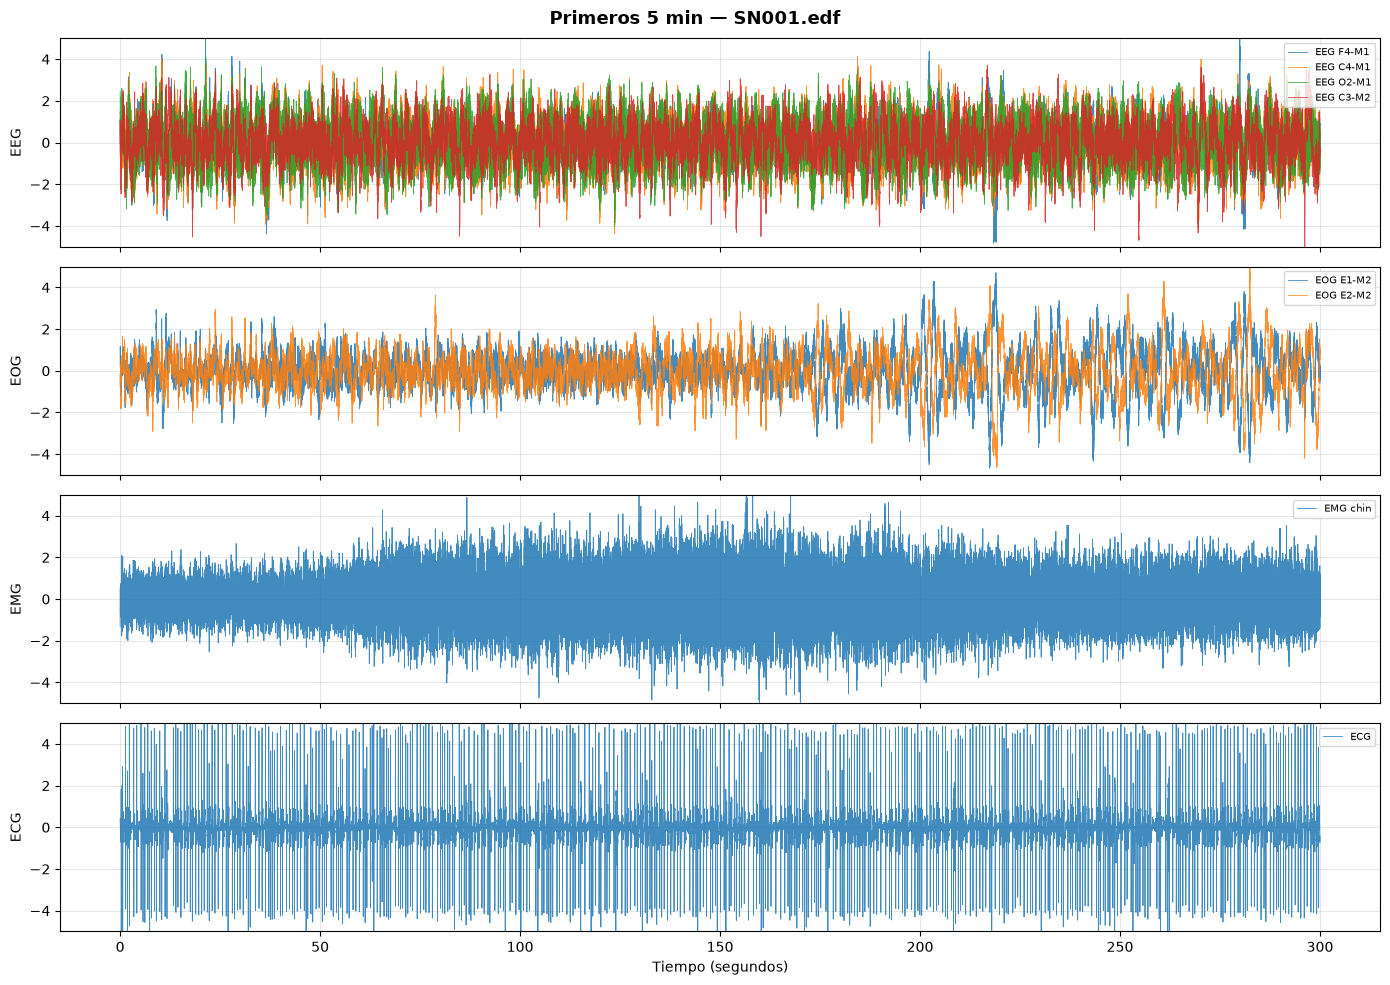

In [73]:
# Recortar los primeros 5 minutos sin cargar toda la grabación en memoria
raw_crop = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=300)

times = raw_crop.times

# Agrupar canales por tipo
channel_groups = {
    group: [ch for ch in raw_crop.ch_names if ch.startswith(group)]
    for group in ["EEG", "EOG", "EMG", "ECG"]
}

# Conservar únicamente grupos presentes en la grabación
channel_groups = {
    group: channels
    for group, channels in channel_groups.items()
    if channels
}

# Crear un subplot por tipo de señal
fig, axes = plt.subplots(
    len(channel_groups),
    1,
    figsize=(14, 10),
    sharex=True
)

axes = np.atleast_1d(axes)

fig.suptitle(
    f"Primeros 5 min — {sample_file}",
    fontsize=13,
    fontweight="bold"
)

for ax, (group, channels) in zip(axes, channel_groups.items()):

    # Extraer solamente los canales del grupo
    group_data = raw_crop.get_data(picks=channels)

    # Normalizar cada canal a media 0 y desvío estándar 1
    group_data = (
        group_data - group_data.mean(axis=1, keepdims=True)
    ) / (
        group_data.std(axis=1, keepdims=True) + 1e-10
    )

    # Graficar los canales superpuestos
    for signal, channel in zip(group_data, channels):
        ax.plot(
            times,
            signal,
            lw=0.6,
            alpha=0.85,
            label=channel
        )

    ax.set_ylabel(group)
    ax.set_ylim(-5, 5)
    ax.legend(loc="upper right", fontsize=7)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Tiempo (segundos)")

plt.tight_layout()
plt.show()

del raw_crop

### Observaciones iniciales sobre las señales crudas

En los primeros 5 minutos del sujeto `SN001` no se observan canales completamente planos ni señales ausentes. Los cuatro canales EEG presentan actividad continua, mientras que las señales EOG muestran variaciones compatibles con movimientos oculares. La señal EMG presenta cambios en su amplitud a lo largo del tiempo, posiblemente asociados con variaciones en la actividad muscular. El ECG muestra picos repetitivos y regulares, vinculados con la actividad cardíaca.


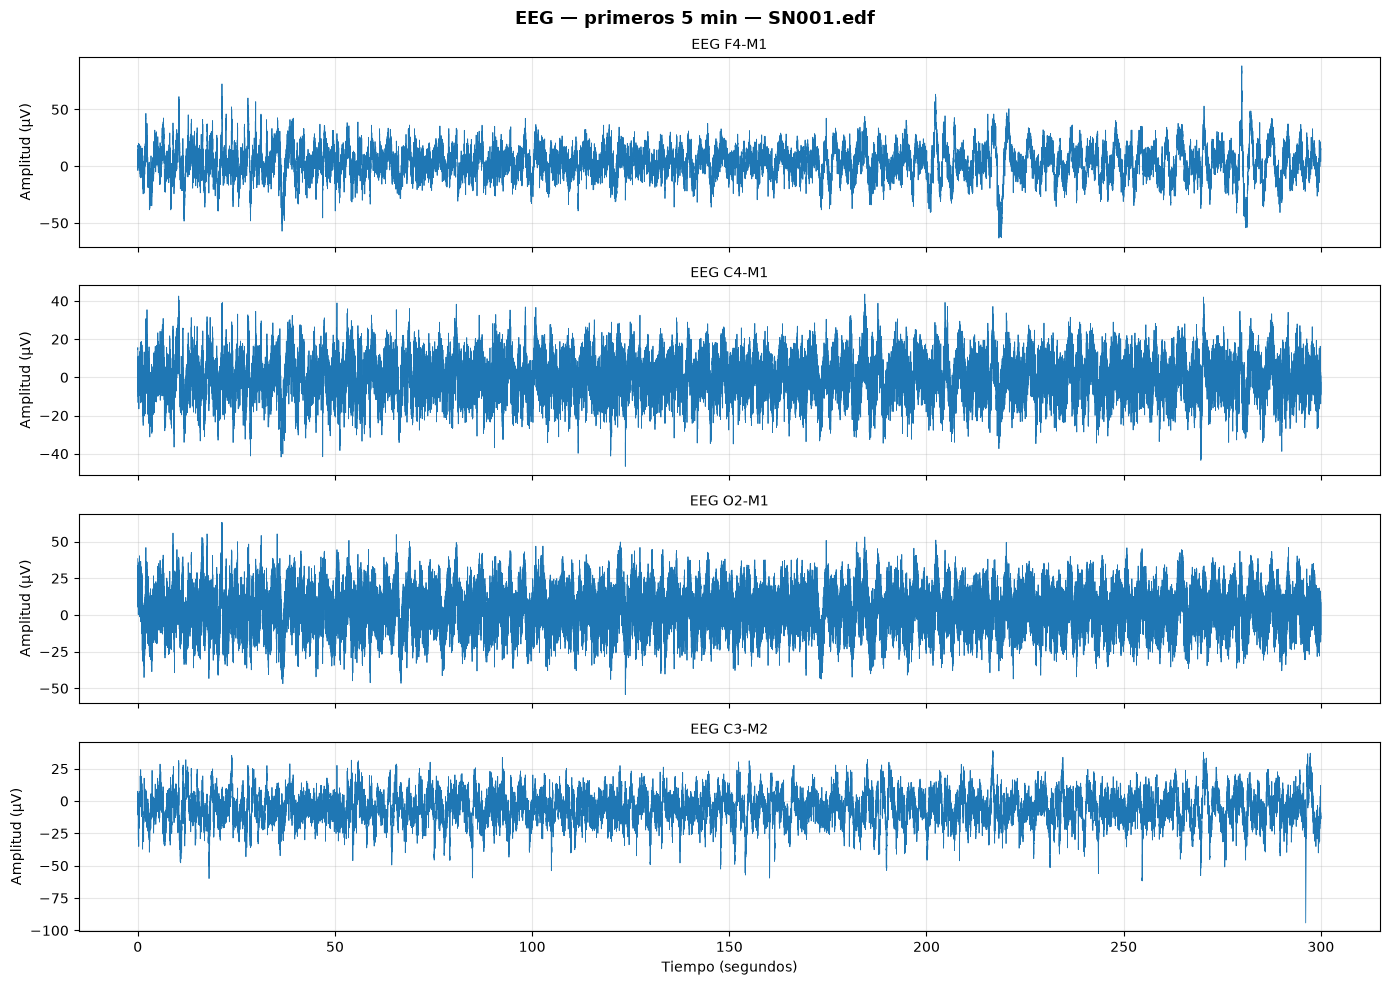

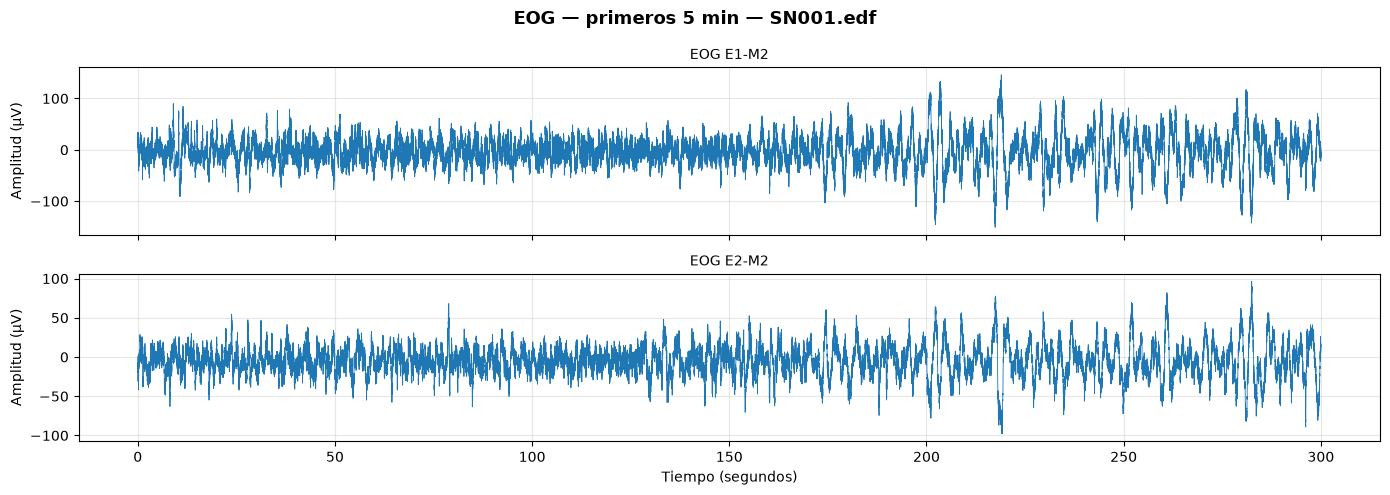

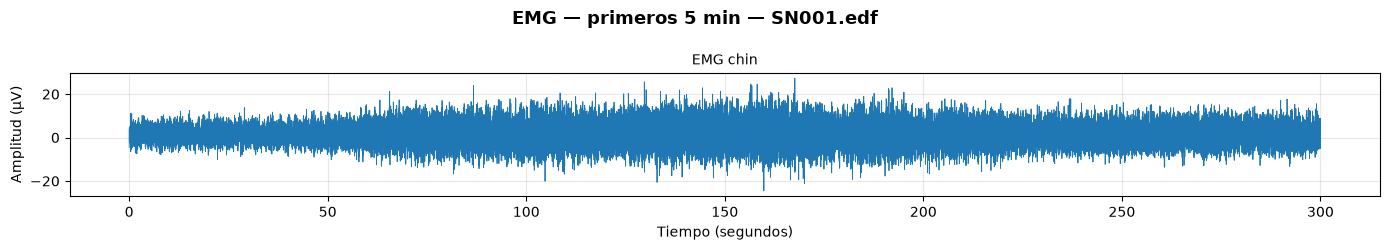

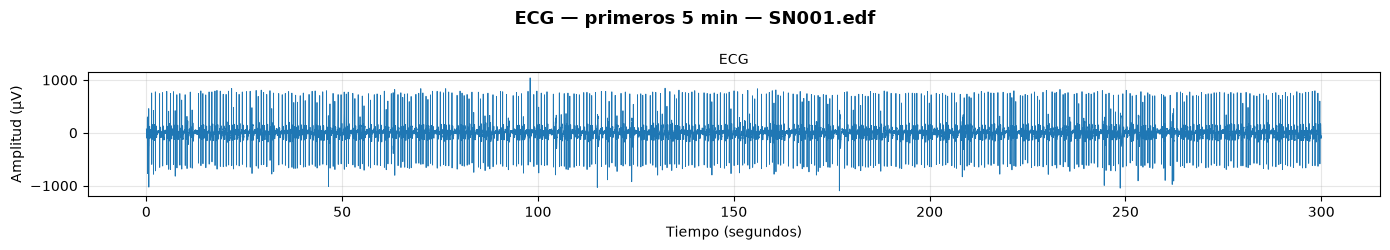

In [74]:
# ============================================================
# Visualización de señales crudas sin normalización
# ============================================================

# Primeros 5 minutos de la grabación
raw_crop = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=300)

times = raw_crop.times

# Agrupar canales según su nombre
channel_groups = {
    group: [ch for ch in raw_crop.ch_names if ch.startswith(group)]
    for group in ["EEG", "EOG", "EMG", "ECG"]
}

# Graficar cada tipo de señal por separado
for group, channels in channel_groups.items():

    if not channels:
        continue

    # Obtener únicamente los canales del grupo y convertir V → µV
    group_data = raw_crop.get_data(picks=channels) * 1e6

    fig, axes = plt.subplots(
        len(channels),
        1,
        figsize=(14, 2.5 * len(channels)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    fig.suptitle(
        f"{group} — primeros 5 min — {sample_file}",
        fontsize=13,
        fontweight="bold"
    )

    for ax, signal_uv, channel in zip(axes, group_data, channels):
        ax.plot(times, signal_uv, linewidth=0.6)
        ax.set_title(channel, fontsize=10)
        ax.set_ylabel("Amplitud (µV)")
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Tiempo (segundos)")

    plt.tight_layout()
    plt.show()

del raw_crop

---
## 4. Análisis de canales en todo el dataset

La idea principal en este punto, es verificar que todos los archivos comparten los mismos canales.  

In [75]:
# ============================================================
# Consistencia de canales, sampling rate y duración
# ============================================================

channel_info = []

for file_name in edf_signals:

    file_path = os.path.join(DATA_PATH, file_name)

    try:
        raw_file = mne.io.read_raw_edf(
            file_path,
            preload=False,
            verbose=False
        )

        channel_info.append({
            "subject": file_name.replace(".edf", ""),
            "n_channels": len(raw_file.ch_names),
            "channels": tuple(sorted(raw_file.ch_names)),
            "sfreq": raw_file.info["sfreq"],
            "duration_h": raw_file.duration / SECONDS_PER_HOUR
        })

        raw_file.close()

    except Exception as error:
        print(f"❌ Error leyendo {file_name}: {error}")


df_info = pd.DataFrame(channel_info)

# Verificar si todos los sujetos tienen los mismos canales
unique_channel_sets = df_info["channels"].nunique()

print(
    f"Conjuntos de canales distintos en el dataset: "
    f"{unique_channel_sets}"
)

if unique_channel_sets == 1:
    print("✅ Todos los archivos tienen exactamente los mismos canales.")
else:
    print("⚠️ Hay variación en los canales — revisar antes de modelar.")
    print(df_info["channels"].value_counts())

# Verificar sampling rates
print(
    f"\nSampling rates presentes: "
    f"{df_info['sfreq'].unique()}"
)

# Resumen general
print("\nResumen general:")
print(
    df_info[
        ["n_channels", "sfreq", "duration_h"]
    ].describe().round(2)
)

Conjuntos de canales distintos en el dataset: 1
✅ Todos los archivos tienen exactamente los mismos canales.

Sampling rates presentes: [256.]

Resumen general:
       n_channels  sfreq  duration_h
count       151.0  151.0      151.00
mean          8.0  256.0        7.58
std           0.0    0.0        1.24
min           8.0  256.0        3.92
25%           8.0  256.0        6.97
50%           8.0  256.0        7.52
75%           8.0  256.0        8.39
max           8.0  256.0       10.93


---
## 5. Distribución de duraciones

Se inspecciona la distribución de duración de las grabaciones para identificar recordings particularmente cortos que puedan requerir una revisión adicional.

Se utiliza un umbral exploratorio de 4 horas únicamente como señal de revisión. Una duración inferior a este valor no implica por sí sola que la grabación sea inválida.

Estadísticas de duración (horas):
  Mínima:   3.92 h
  Máxima:   10.93 h
  Promedio: 7.58 h
  Mediana:  7.52 h

Grabaciones cortas (< 4.0 h): 1


,subject,duration_h
60,SN062,3.917778


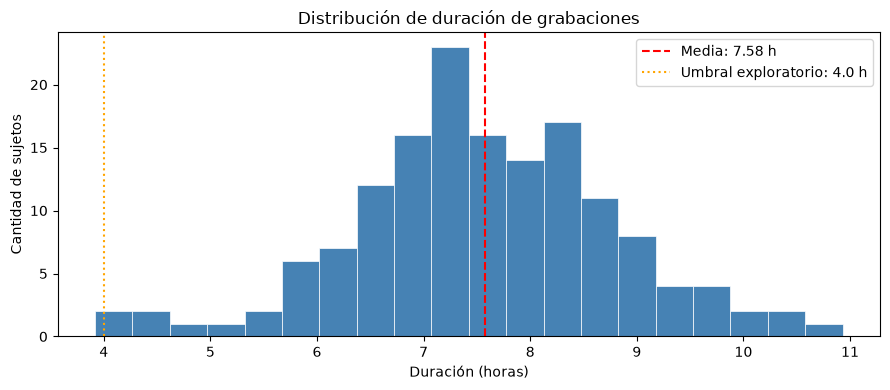

In [76]:
durations_h = df_info["duration_h"]

print("Estadísticas de duración (horas):")
print(f"  Mínima:   {durations_h.min():.2f} h")
print(f"  Máxima:   {durations_h.max():.2f} h")
print(f"  Promedio: {durations_h.mean():.2f} h")
print(f"  Mediana:  {durations_h.median():.2f} h")

# Identificar grabaciones particularmente cortas
short_recordings = df_info[
    durations_h < SHORT_RECORDING_THRESHOLD_H
]

if not short_recordings.empty:
    print(
        f"\nGrabaciones cortas "
        f"(< {SHORT_RECORDING_THRESHOLD_H} h): "
        f"{len(short_recordings)}"
    )
    display(short_recordings[["subject", "duration_h"]])
else:
    print(
        f"\n✅ Ninguna grabación menor a "
        f"{SHORT_RECORDING_THRESHOLD_H} horas."
    )

# Histograma
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(
    durations_h,
    bins=20,
    color="steelblue",
    edgecolor="white",
    linewidth=0.5
)
ax.axvline(
    durations_h.mean(),
    color="red",
    ls="--",
    label=f"Media: {durations_h.mean():.2f} h"
)
ax.axvline(
    SHORT_RECORDING_THRESHOLD_H,
    color="orange",
    ls=":",
    label=f"Umbral exploratorio: {SHORT_RECORDING_THRESHOLD_H} h"
)
ax.set_xlabel("Duración (horas)")
ax.set_ylabel("Cantidad de sujetos")
ax.set_title("Distribución de duración de grabaciones")
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Leer y explorar labels (hypnograms)

El **hypnogram** representa la secuencia temporal de etapas de sueño, epoch por epoch. En este dataset, cada sleep stage tiene una duración de 30 segundos.

Estas etapas constituyen la variable objetivo del problema de clasificación.

In [77]:
def load_hypnogram(txt_path):
    """
    Lee el archivo de anotaciones y devuelve solo los sleep stages.
    Verifica que cada sleep stage tenga la duración esperada.
    """

    df = pd.read_csv(txt_path)

    # Limpiar nombres de columnas y anotaciones
    df.columns = df.columns.str.strip()
    df["Annotation"] = df["Annotation"].str.strip()

    # Quedarse solo con las filas correspondientes a sleep stages
    stages = df[
        df["Annotation"].str.startswith("Sleep stage", na=False)
    ].copy()

    # Verificar duración de los epochs
    invalid_duration = ~np.isclose(
        stages["Duration"].astype(float),
        EPOCH_DURATION_S
    )

    if invalid_duration.any():
        raise ValueError(
            f"Se encontraron sleep stages con duración distinta de "
            f"{EPOCH_DURATION_S} s en {os.path.basename(txt_path)}"
        )

    return stages.reset_index(drop=True)


# Leer labels del sujeto de ejemplo
sample_labels_path = os.path.join(
    LABELS_PATH,
    sample_file.replace(".edf", "_sleepscoring.txt")
)

sample_labels = load_hypnogram(sample_labels_path)

print(f"Epochs totales: {len(sample_labels)}")
print(
    f"Duración cubierta: "
    f"{len(sample_labels) * EPOCH_DURATION_H:.2f} horas"
)
print()
print("Distribución de stages:")
print(sample_labels["Annotation"].value_counts())
print()
print("Primeras filas:")
display(sample_labels.head(10))

Epochs totales: 854
Duración cubierta: 7.12 horas

Distribución de stages:
Annotation
Sleep stage N2    430
Sleep stage W     151
Sleep stage R     141
Sleep stage N1    109
Sleep stage N3     23
Name: count, dtype: int64

Primeras filas:


,Date,Time,Recording onset,Duration,Annotation,Linked channel
0,01.01.01,23.59.30,0.0,30,Sleep stage W,
1,02.01.01,00.00.00,30.0,30,Sleep stage W,
2,02.01.01,00.00.30,60.0,30,Sleep stage W,
3,02.01.01,00.01.00,90.0,30,Sleep stage W,
4,02.01.01,00.01.30,120.0,30,Sleep stage W,
5,02.01.01,00.02.00,150.0,30,Sleep stage W,
6,02.01.01,00.02.30,180.0,30,Sleep stage W,
7,02.01.01,00.03.00,210.0,30,Sleep stage W,
8,02.01.01,00.03.30,240.0,30,Sleep stage N1,
9,02.01.01,00.04.00,270.0,30,Sleep stage N1,


### 6.1 Validación temporal de los sleep stages

Antes de asociar las anotaciones con segmentos de la señal, se verifica la estructura temporal de los archivos de scoring.

Para cada sujeto se analiza:

- el instante de inicio del primer sleep stage (`Recording onset`);
- si los onsets consecutivos están separados regularmente por 30 segundos;
- la cantidad total de sleep stages disponibles.

Esta comprobación permite determinar si los labels pueden asociarse directamente con epochs consecutivos de la señal o si es necesario considerar un desplazamiento temporal durante el procesamiento.

In [78]:
label_timing = []

for file_name in edf_signals:

    subject = file_name.replace(".edf", "")
    labels_path = os.path.join(
        LABELS_PATH,
        file_name.replace(".edf", "_sleepscoring.txt")
    )

    subject_labels = load_hypnogram(labels_path)
    onsets_s = subject_labels["Recording onset"].to_numpy(dtype=float)

    regular_30s = (
        len(onsets_s) <= 1
        or np.allclose(np.diff(onsets_s), EPOCH_DURATION_S)
    )

    starts_at_zero = (
        len(onsets_s) > 0
        and np.isclose(onsets_s[0], 0.0)
    )

    label_timing.append({
        "subject": subject,
        "n_labels": len(subject_labels),
        "first_onset_s": onsets_s[0] if len(onsets_s) else np.nan,
        "regular_30s": regular_30s,
        "starts_at_zero": starts_at_zero
    })


df_label_timing = pd.DataFrame(label_timing)

print(
    f"Sujetos con separación regular de {EPOCH_DURATION_S} s: "
    f"{df_label_timing['regular_30s'].sum()} / {len(df_label_timing)}"
)

print(
    f"Sujetos cuyo primer stage comienza en t=0: "
    f"{df_label_timing['starts_at_zero'].sum()} / {len(df_label_timing)}"
)

print(
    "Onsets iniciales encontrados: "
    f"{sorted(df_label_timing['first_onset_s'].dropna().unique())}"
)

# Mostrar únicamente casos que requieren atención
# Un onset inicial distinto de cero no implica un archivo inválido,
# pero sí requiere respetar Recording onset al alinear señal y labels.
timing_issues = df_label_timing[
    (~df_label_timing["regular_30s"])
    | (~df_label_timing["starts_at_zero"])
]

if timing_issues.empty:
    print("✅ Los sleep stages son regulares y comienzan en t=0 en todos los sujetos.")
else:
    print("⚠️ Se encontraron casos que requieren considerar explícitamente el onset:")
    display(timing_issues)

Sujetos con separación regular de 30 s: 151 / 151
Sujetos cuyo primer stage comienza en t=0: 151 / 151
Onsets iniciales encontrados: [np.float64(0.0)]
✅ Los sleep stages son regulares y comienzan en t=0 en todos los sujetos.


### 6.2 Hypnogram visual

El hypnogram permite visualizar la arquitectura temporal del sueño del sujeto de ejemplo y observar la sucesión de etapas a lo largo de la noche.

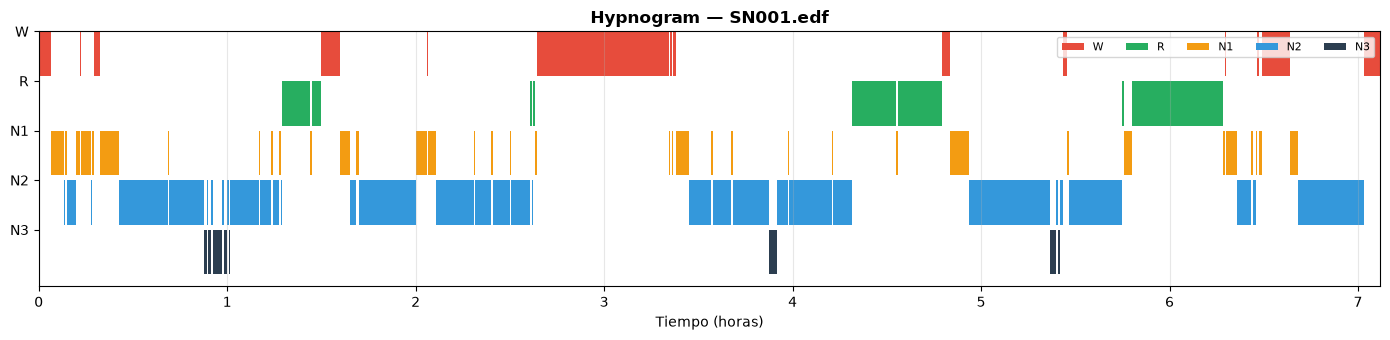

In [79]:
# Posición vertical de cada etapa
stage_num = sample_labels["Annotation"].map(STAGE_TO_Y)

# Usar el onset real de cada label
sample_time_h = (
    sample_labels["Recording onset"].astype(float)
    / SECONDS_PER_HOUR
)

# Color correspondiente a cada epoch
colors = sample_labels["Annotation"].map(STAGE_COLORS).fillna("gray")

fig, ax = plt.subplots(figsize=(14, 3.5))

ax.bar(
    sample_time_h,
    height=0.9,
    bottom=stage_num,
    width=EPOCH_DURATION_H,
    align="edge",
    color=colors
)

ax.set_yticks(list(STAGE_TO_Y.values()))
ax.set_yticklabels([
    stage.replace("Sleep stage ", "")
    for stage in STAGE_ORDER
])
ax.invert_yaxis()

ax.set_xlabel("Tiempo (horas)")
ax.set_title(f"Hypnogram — {sample_file}", fontweight="bold")
ax.set_xlim(
    0,
    (sample_labels["Recording onset"].astype(float).max() + EPOCH_DURATION_S)
    / SECONDS_PER_HOUR
)
ax.grid(axis="x", alpha=0.3)

# Leyenda
stages_present = set(sample_labels["Annotation"].unique())

legend_elements = [
    Patch(
        facecolor=STAGE_COLORS[stage],
        label=stage.replace("Sleep stage ", "")
    )
    for stage in STAGE_ORDER
    if stage in stages_present
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=8,
    ncol=5
)

plt.tight_layout()
plt.show()

---
## 7. Distribución de clases — todo el dataset

Se analiza la distribución de las etapas de sueño en el dataset original, antes de aplicar exclusiones por calidad.

El predominio de N2 puede favorecer a la clase mayoritaria si el entrenamiento y la evaluación no consideran el desbalance, por lo que posteriormente se utilizarán métricas que evalúen el desempeño entre clases y estrategias de balanceo cuando corresponda.

In [80]:
# ============================================================
# Distribución global de sleep stages
# ============================================================

all_stages = []

for file_name in edf_signals:

    labels_path = os.path.join(
        LABELS_PATH,
        file_name.replace(".edf", "_sleepscoring.txt")
    )

    if not os.path.exists(labels_path):
        continue

    try:
        subject_labels = load_hypnogram(labels_path)
        all_stages.extend(subject_labels["Annotation"])

    except Exception as error:
        print(f"❌ Error leyendo {file_name}: {error}")


# Conteos y porcentajes
stage_counts = pd.Series(all_stages).value_counts()
stage_counts = stage_counts.reindex(STAGE_ORDER, fill_value=0)
stage_pct = stage_counts / stage_counts.sum() * 100

stage_summary = pd.DataFrame({
    "Epochs": stage_counts,
    "Porcentaje": stage_pct.round(1)
})

print("Distribución global de sleep stages:")
display(stage_summary)

print(f"Total epochs: {stage_counts.sum():,}")
print(
    f"Horas totales anotadas: "
    f"{stage_counts.sum() * EPOCH_DURATION_H:.1f} h"
)

# Ratio entre clase mayoritaria y minoritaria
ratio = stage_counts.max() / stage_counts.min()
print(f"Ratio de desbalance (max/min): {ratio:.1f}x")

Distribución global de sleep stages:


,Epochs,Porcentaje
Sleep stage W,23686,17.3
Sleep stage R,21255,15.5
Sleep stage N1,15548,11.3
Sleep stage N2,50083,36.5
Sleep stage N3,26671,19.4


Total epochs: 137,243
Horas totales anotadas: 1143.7 h
Ratio de desbalance (max/min): 3.2x


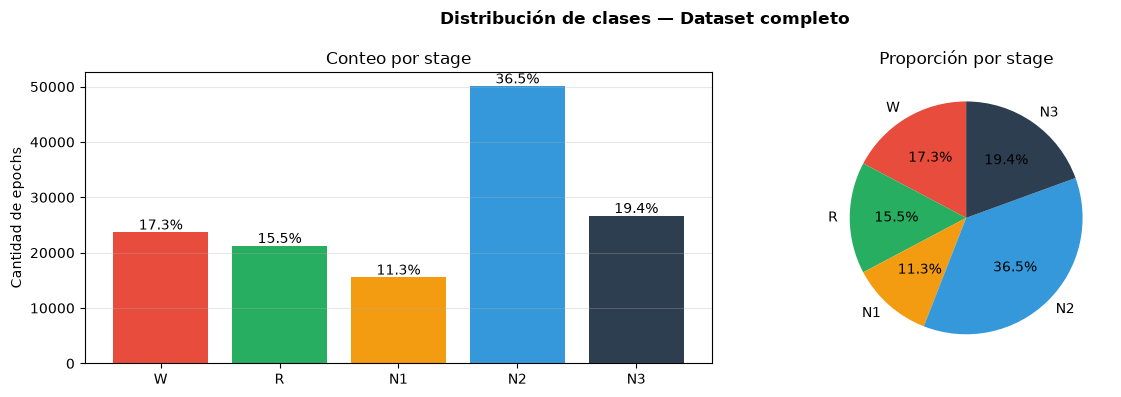

In [81]:
# Visualización
short_labels = [
    stage.replace("Sleep stage ", "")
    for stage in stage_counts.index
]

colors = [
    STAGE_COLORS[stage]
    for stage in stage_counts.index
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(
    "Distribución de clases — Dataset completo",
    fontweight="bold"
)

# Conteos
ax1.bar(
    short_labels,
    stage_counts,
    color=colors
)

for i, (count, pct) in enumerate(zip(stage_counts, stage_pct)):
    ax1.text(
        i,
        count + stage_counts.max() * 0.01,
        f"{pct:.1f}%",
        ha="center"
    )

ax1.set_ylabel("Cantidad de epochs")
ax1.set_title("Conteo por stage")
ax1.grid(axis="y", alpha=0.3)

# Proporciones
ax2.pie(
    stage_counts,
    labels=short_labels,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90
)

ax2.set_title("Proporción por stage")

plt.tight_layout()
plt.show()

---
## 8. Estadísticas descriptivas por canal


Para el sujeto de ejemplo se calculan estadísticas básicas de amplitud para cada canal.

El objetivo es verificar las escalas de las señales, detectar posibles valores faltantes y observar valores extremos antes de aplicar el procesamiento.

El análisis de segmentos planos y amplitudes sospechosas se realiza posteriormente mediante criterios específicos de control de calidad.


In [82]:
# ============================================================
# Estadísticas descriptivas por canal
# ============================================================

raw_stats = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

stats_rows = []

for channel in raw_stats.ch_names:

    # Cargar únicamente el canal actual
    signal_uv = (
        raw_stats.get_data(picks=[channel])[0] * 1e6
    )

    stats_rows.append({
        "Canal": channel,
        "Media (µV)": signal_uv.mean(),
        "Std (µV)": signal_uv.std(),
        "Min (µV)": signal_uv.min(),
        "Max (µV)": signal_uv.max(),
        "Rango (µV)": signal_uv.max() - signal_uv.min(),
        "% NaN": np.isnan(signal_uv).mean() * 100
    })


df_stats = (
    pd.DataFrame(stats_rows)
    .set_index("Canal")
    .round(3)
)

display(df_stats)

if df_stats["% NaN"].max() > 0:
    print("⚠️ Hay valores NaN en algún canal.")
else:
    print("✅ No hay valores NaN en el sujeto analizado.")

raw_stats.close()

,Media (µV),Std (µV),Min (µV),Max (µV),Rango (µV),% NaN
Canal,,,,,,
EEG F4-M1,3.706,39.765,-800.000,800.000,1600.000,0.0
EEG C4-M1,0.079,39.324,-800.000,800.000,1600.000,0.0
EEG O2-M1,3.248,29.999,-800.000,800.000,1600.000,0.0
EEG C3-M2,-5.548,47.948,-800.000,800.000,1600.000,0.0
EMG chin,1.611,4.777,-402.191,345.501,747.692,0.0
EOG E1-M2,-3.181,46.648,-800.000,800.000,1600.000,0.0
EOG E2-M2,-4.836,46.175,-800.000,800.000,1600.000,0.0
ECG,7.439,122.414,-2400.000,2400.000,4800.000,0.0


✅ No hay valores NaN en el sujeto analizado.


---
## 9. Power Spectral Density (PSD)

La PSD muestra cómo se distribuye la potencia de la señal en función de la frecuencia.

Para mantener un criterio consistente en todo el proyecto, se utilizan las siguientes bandas:

| Banda | Rango | Relevancia |
|-------|-------|------------|
| Delta | 0.5–4 Hz | N3 (sueño profundo) |
| Theta | 4–8 Hz | N1, REM |
| Alpha | 8–12 Hz | W (relajado con ojos cerrados) |
| Sigma | 12–15 Hz | N2 (sleep spindles) |
| Beta | 15–30 Hz | W (activo) |

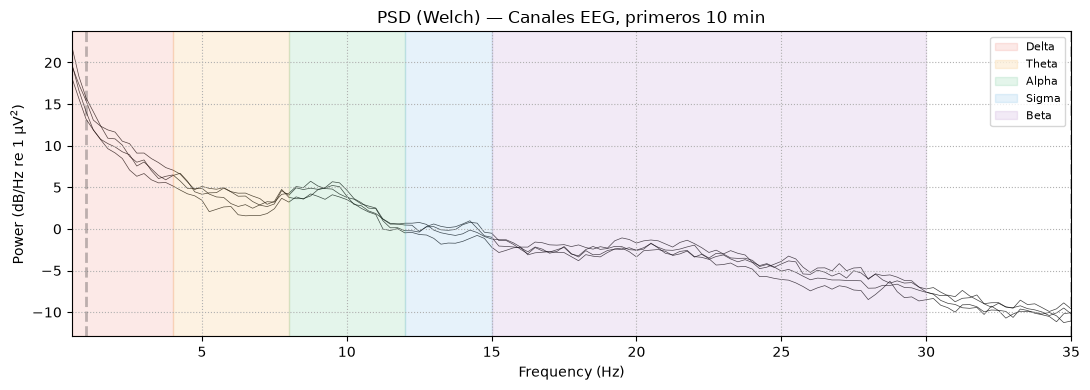

In [83]:
# ============================================================
# Densidad espectral de potencia (PSD) en canales EEG
# ============================================================

# Primeros 10 minutos de la grabación
raw_psd = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=600)

# Seleccionar canales EEG
psd_eeg_channels = [
    ch for ch in raw_psd.ch_names
    if ch.startswith("EEG")
]

# PSD mediante el método de Welch
spectrum = raw_psd.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=35,
    n_fft=1024,
    picks=psd_eeg_channels
)

fig, ax = plt.subplots(figsize=(11, 4))

spectrum.plot(
    axes=ax,
    show=False
)

ax.set_title("PSD (Welch) — Canales EEG, primeros 10 min")

band_colors = {
    "Delta": "#e74c3c",
    "Theta": "#f39c12",
    "Alpha": "#27ae60",
    "Sigma": "#3498db",
    "Beta": "#9b59b6"
}

for band, (fmin, fmax) in FREQ_BANDS.items():
    ax.axvspan(
        fmin,
        fmax,
        color=band_colors[band],
        alpha=0.12,
        label=band
    )

ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

raw_psd.close()

---
## 10. PSD comparado por sleep stage

Las etapas pueden presentar diferencias en su contenido espectral, lo cual será la base del feature engineering.  

In [84]:
# ============================================================
# PSD promedio por sleep stage
# ============================================================

stage_eeg_channel = "EEG C4-M1"

raw_stage = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

stage_sfreq = raw_stage.info["sfreq"]
stage_epoch_samples = int(EPOCH_DURATION_S * stage_sfreq)

# Cargar únicamente el canal EEG seleccionado
stage_signal = raw_stage.get_data(
    picks=[stage_eeg_channel]
)[0]

stage_labels = load_hypnogram(sample_labels_path)

psd_by_stage = {
    stage: []
    for stage in STAGE_ORDER
}

freqs_plot = None

for _, label in stage_labels.iterrows():

    stage = label["Annotation"]

    if stage not in psd_by_stage:
        continue

    onset_s = float(label["Recording onset"])
    start = int(round(onset_s * stage_sfreq))
    end = start + stage_epoch_samples

    if end > len(stage_signal):
        continue

    epoch_signal = stage_signal[start:end]

    freqs, psd = welch(
        epoch_signal,
        fs=stage_sfreq,
        nperseg=1024
    )

    freq_mask = (freqs >= 0.5) & (freqs <= 35)
    freqs_plot = freqs[freq_mask]

    psd_by_stage[stage].append(
        psd[freq_mask]
    )

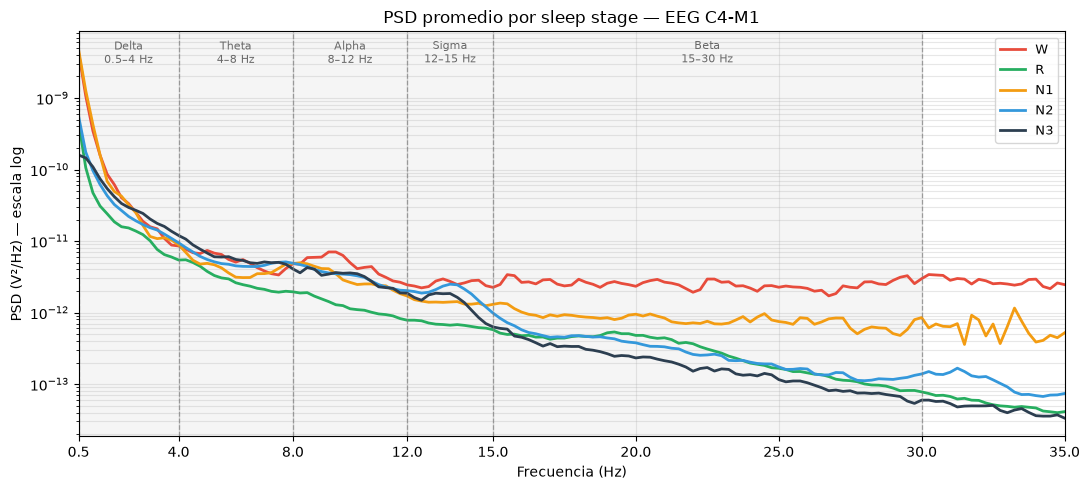

In [85]:
fig, ax = plt.subplots(figsize=(11, 5))

# PSD promedio de cada stage
for stage, psds in psd_by_stage.items():

    if not psds:
        continue

    mean_psd = np.mean(psds, axis=0)

    ax.semilogy(
        freqs_plot,
        mean_psd,
        color=STAGE_COLORS.get(stage, "gray"),
        lw=2,
        label=stage.replace("Sleep stage ", "")
    )

# Bandas de frecuencia
for band, (fmin, fmax) in FREQ_BANDS.items():

    ax.axvspan(
        fmin,
        fmax,
        color="gray",
        alpha=0.08
    )

    ax.axvline(
        fmin,
        color="gray",
        linestyle="--",
        linewidth=0.9,
        alpha=0.7
    )

    ax.text(
        (fmin + fmax) / 2,
        0.98,
        f"{band}\n{fmin:g}–{fmax:g} Hz",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        color="dimgray"
    )

# Último límite de las bandas definidas
ax.axvline(
    max(fmax for _, fmax in FREQ_BANDS.values()),
    color="gray",
    linestyle="--",
    linewidth=0.9,
    alpha=0.7
)

ax.set(
    xlabel="Frecuencia (Hz)",
    ylabel="PSD (V²/Hz) — escala log",
    title=f"PSD promedio por sleep stage — {stage_eeg_channel}",
    xlim=(0.5, 35)
)

ax.set_xticks([0.5, 4, 8, 12, 15, 20, 25, 30, 35])
ax.legend(fontsize=9)
ax.grid(which="both", alpha=0.3)

plt.tight_layout()
plt.show()

raw_stage.close()

### PSD promedio por etapa de sueño

En esta sección se utilizó el canal EEG central `EEG C4-M1` y se dividió la señal en epochs de 30 segundos respetando el `Recording onset` de cada anotación. Para cada epoch se calculó la PSD mediante el método de Welch y luego se agruparon los resultados según la etapa de sueño (`W`, `R`, `N1`, `N2` y `N3`).

Finalmente, se graficó la PSD promedio de cada etapa y se marcaron las bandas frecuenciales utilizadas en el proyecto:

* **Delta:** 0.5–4 Hz
* **Theta:** 4–8 Hz
* **Alpha:** 8–12 Hz
* **Sigma:** 12–15 Hz
* **Beta:** 15–30 Hz

Como observación inicial, se aprecia que `N3` presenta mayor potencia en el rango de frecuencias bajas, mientras que `W` conserva mayor potencia en frecuencias medias y altas. Las diferencias entre etapas no son perfectamente separables, pero muestran que el contenido frecuencial del EEG varía según el sleep stage.

---
## 11. Calidad de señal — detección de problemas

Antes de modelar, se realiza un screening exploratorio de calidad sobre los canales EEG.

En esta EDA se utilizan dos criterios para marcar un epoch como sospechoso:

- **Amplitud elevada:** al menos una muestra con `|amplitud| > 500 µV`.
- **Segmento plano:** señal exactamente constante durante al menos 1 segundo.

Estos criterios se utilizan para detectar casos que requieren revisión; no implican un descarte automático del epoch o del sujeto.

In [86]:
def has_flat_segment(signal, min_samples):
    """True si existe un tramo de al menos min_samples valores iguales."""

    repeated = np.diff(signal) == 0
    boundaries = np.r_[True, ~repeated, True]
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return run_lengths.max() >= min_samples


def check_epoch(epoch_data_uv, channel_names, flat_samples):
    """Devuelve las razones por las que un epoch se marca como sospechoso."""

    reasons = []

    for signal, channel in zip(epoch_data_uv, channel_names):

        if np.max(np.abs(signal)) > AMPLITUDE_THRESHOLD_UV:
            reasons.append(
                f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {channel}"
            )

        if has_flat_segment(signal, flat_samples):
            reasons.append(
                f"segmento plano en {channel}"
            )

    return reasons

### 11.1 Análisis para un sujeto de ejemplo

In [87]:
# ============================================================
# Detección de epochs EEG sospechosos: sujeto de ejemplo
# ============================================================

raw_qc = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

qc_sfreq = raw_qc.info["sfreq"]
qc_epoch_samples = int(EPOCH_DURATION_S * qc_sfreq)
qc_flat_samples = int(FLAT_DURATION_S * qc_sfreq)

qc_eeg_channels = [
    ch for ch in raw_qc.ch_names
    if ch.startswith("EEG")
]

qc_eeg_data = raw_qc.get_data(
    picks=qc_eeg_channels
)

qc_labels = load_hypnogram(sample_labels_path)

bad_epochs = []
epochs_checked = 0

for i, label in qc_labels.iterrows():

    onset_s = float(label["Recording onset"])
    start = int(round(onset_s * qc_sfreq))
    end = start + qc_epoch_samples

    if end > raw_qc.n_times:
        continue

    epoch_uv = qc_eeg_data[:, start:end] * 1e6

    reasons = check_epoch(
        epoch_uv,
        qc_eeg_channels,
        qc_flat_samples
    )

    epochs_checked += 1

    if reasons:
        bad_epochs.append({
            "epoch": i,
            "onset_s": onset_s,
            "stage": label["Annotation"],
            "razones": ", ".join(reasons)
        })


df_bad = pd.DataFrame(bad_epochs)
sample_pct_bad = (
    len(df_bad) / epochs_checked * 100
    if epochs_checked
    else np.nan
)

print(
    f"Epochs sospechosos: "
    f"{len(df_bad)} / {epochs_checked} ({sample_pct_bad:.1f}%)"
)

if not df_bad.empty:
    print("\nDistribución por stage:")
    print(df_bad["stage"].value_counts())

    print("\nEjemplos:")
    display(df_bad.head(10))

raw_qc.close()
del qc_eeg_data

Epochs sospechosos: 53 / 854 (6.2%)

Distribución por stage:
stage
Sleep stage W     24
Sleep stage N1    14
Sleep stage N2     9
Sleep stage R      6
Name: count, dtype: int64

Ejemplos:


,epoch,onset_s,stage,razones
0,26,780.0,Sleep stage W,amplitud>500µV en EEG O2-M1
1,34,1020.0,Sleep stage N1,amplitud>500µV en EEG O2-M1
2,35,1050.0,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
3,44,1320.0,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
4,53,1590.0,Sleep stage N2,amplitud>500µV en EEG C3-M2
5,81,2430.0,Sleep stage N2,amplitud>500µV en EEG C3-M2
6,87,2610.0,Sleep stage N2,amplitud>500µV en EEG C3-M2
7,173,5190.0,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
8,179,5370.0,Sleep stage R,amplitud>500µV en EEG F4-M1
9,180,5400.0,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."


### 11.2 Análisis global de calidad por sujeto

En esta sección se aplica el mismo screening exploratorio a todos los sujetos del dataset.

Para cada recording se calcula:

- duración de la grabación;
- cantidad de canales;
- frecuencia de muestreo;
- cantidad de labels disponibles;
- cantidad de epochs efectivamente evaluados;
- cantidad y porcentaje de epochs EEG sospechosos.

La correspondencia entre señal y sleep stage se realiza utilizando `Recording onset`, en lugar de asumir que el primer label comienza necesariamente en el segundo cero.

Un epoch se marca como sospechoso si al menos un canal EEG presenta una amplitud absoluta superior a `500 µV` o permanece exactamente plano durante al menos un segundo.

**Aclaración:** este análisis es exploratorio. Los epochs detectados no se eliminan automáticamente; el objetivo es identificar sujetos o segmentos que requieran una revisión más detallada durante el preprocessing.

In [88]:
# ============================================================
# Análisis global de calidad de señal por sujeto
# ============================================================

subject_summary = []
all_bad_epochs = []

for file_name in edf_signals:

    subject = file_name.replace(".edf", "")
    edf_path = os.path.join(DATA_PATH, file_name)
    labels_path = os.path.join(
        LABELS_PATH,
        file_name.replace(".edf", "_sleepscoring.txt")
    )

    try:
        raw_subject = mne.io.read_raw_edf(
            edf_path,
            preload=False,
            verbose=False
        )

        subject_sfreq = raw_subject.info["sfreq"]
        subject_epoch_samples = int(
            EPOCH_DURATION_S * subject_sfreq
        )
        subject_flat_samples = int(
            FLAT_DURATION_S * subject_sfreq
        )

        subject_eeg_channels = [
            ch for ch in raw_subject.ch_names
            if ch.startswith("EEG")
        ]

        subject_eeg_data = raw_subject.get_data(
            picks=subject_eeg_channels
        )

        subject_labels = load_hypnogram(labels_path)

        bad_count = 0
        epochs_checked = 0

        for i, label in subject_labels.iterrows():

            onset_s = float(label["Recording onset"])
            start = int(round(onset_s * subject_sfreq))
            end = start + subject_epoch_samples

            # Ignorar labels que excedan la señal disponible
            if end > raw_subject.n_times:
                continue

            epoch_uv = subject_eeg_data[:, start:end] * 1e6

            reasons = check_epoch(
                epoch_uv,
                subject_eeg_channels,
                subject_flat_samples
            )

            epochs_checked += 1

            if reasons:
                bad_count += 1

                all_bad_epochs.append({
                    "subject": subject,
                    "epoch": i,
                    "onset_s": onset_s,
                    "stage": label["Annotation"],
                    "reasons": ", ".join(reasons)
                })

        subject_summary.append({
            "subject": subject,
            "duration_h": raw_subject.duration / SECONDS_PER_HOUR,
            "n_channels": len(raw_subject.ch_names),
            "sfreq": subject_sfreq,
            "n_labels": len(subject_labels),
            "epochs_checked": epochs_checked,
            "bad_epochs": bad_count,
            "pct_bad": (
                100 * bad_count / epochs_checked
                if epochs_checked
                else np.nan
            )
        })

        raw_subject.close()
        del subject_eeg_data

    except Exception as error:
        print(f"❌ Error procesando {file_name}: {error}")


# Resultados
df_subject_summary = pd.DataFrame(subject_summary)
df_all_bad_epochs = pd.DataFrame(all_bad_epochs)

df_subject_summary["duration_h"] = (
    df_subject_summary["duration_h"].round(2)
)

df_subject_summary["pct_bad"] = (
    df_subject_summary["pct_bad"].round(1)
)

print(f"Sujetos procesados: {len(df_subject_summary)}")
print(f"Epochs sospechosos totales: {len(df_all_bad_epochs)}")

display(df_subject_summary.head())

Sujetos procesados: 151
Epochs sospechosos totales: 11610


,subject,duration_h,n_channels,sfreq,n_labels,epochs_checked,bad_epochs,pct_bad
0,SN001,7.12,8,256.0,854,854,53,6.2
1,SN002,7.14,8,256.0,856,856,35,4.1
2,SN003,7.95,8,256.0,954,954,77,8.1
3,SN004,8.47,8,256.0,1016,1016,13,1.3
4,SN005,8.00,8,256.0,959,959,110,11.5


In [89]:
# Sujetos con mayor porcentaje de epochs sospechosos
df_subject_summary_sorted = (
    df_subject_summary
    .sort_values("pct_bad", ascending=False)
    .reset_index(drop=True)
)

display(df_subject_summary_sorted.head(15))

,subject,duration_h,n_channels,sfreq,n_labels,epochs_checked,bad_epochs,pct_bad
0,SN032,9.90,8,256.0,1188,1188,1134,95.5
1,SN033,4.35,8,256.0,522,522,423,81.0
2,SN020,7.90,8,256.0,948,948,400,42.2
3,SN133,8.29,8,256.0,995,995,328,33.0
4,SN049,6.68,8,256.0,801,801,256,32.0
5,SN018,7.18,8,256.0,862,862,234,27.1
6,SN072,8.82,8,256.0,1058,1058,218,20.6
7,SN079,9.31,8,256.0,1117,1117,222,19.9
8,SN115,7.14,8,256.0,857,857,157,18.3
9,SN125,10.02,8,256.0,1202,1202,219,18.2


### 11.3 Análisis de sujetos con alta proporción de epochs sospechosos

Los sujetos con al menos `70%` de epochs sospechosos se consideran casos extremos y se seleccionan automáticamente para una revisión detallada.

Además, se incluye como comparación el siguiente sujeto con mayor porcentaje de epochs sospechosos. Esto permite evaluar si un porcentaje elevado, pero menos extremo, justifica por sí solo excluir un recording completo.

In [90]:
extreme_subjects = (
    df_subject_summary
    .loc[
        df_subject_summary["pct_bad"] >= REVIEW_THRESHOLD_PCT,
        ["subject", "pct_bad"]
    ]
    .sort_values("pct_bad", ascending=False)["subject"]
    .tolist()
)

comparison_subjects = (
    df_subject_summary
    .loc[
        ~df_subject_summary["subject"].isin(extreme_subjects),
        ["subject", "pct_bad"]
    ]
    .nlargest(1, "pct_bad")["subject"]
    .tolist()
)

SUBJECTS_TO_REVIEW = extreme_subjects + comparison_subjects

print("Sujetos extremos:", extreme_subjects)
print("Sujeto de comparación:", comparison_subjects)
print("Sujetos a revisar:", SUBJECTS_TO_REVIEW)

Sujetos extremos: ['SN032', 'SN033']
Sujeto de comparación: ['SN020']
Sujetos a revisar: ['SN032', 'SN033', 'SN020']


In [91]:
# ============================================================
# Análisis detallado de sujetos seleccionados
# ============================================================


def analyze_subject_quality(subject_id):

    edf_path = os.path.join(DATA_PATH, f"{subject_id}.edf")
    labels_path = os.path.join(
        LABELS_PATH,
        f"{subject_id}_sleepscoring.txt"
    )

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose=False
    )

    sfreq = raw.info["sfreq"]
    epoch_samples = int(EPOCH_DURATION_S * sfreq)
    flat_samples = int(FLAT_DURATION_S * sfreq)

    eeg_channels = [
        ch for ch in raw.ch_names
        if ch.startswith("EEG")
    ]

    eeg_data = raw.get_data(picks=eeg_channels)
    labels = load_hypnogram(labels_path)

    columns = [
        "subject",
        "epoch",
        "time_h",
        "stage",
        "amplitude",
        "flat",
        "n_channels",
        "amplitude_channels",
        "flat_channels"
    ]

    results = []
    epochs_checked = 0

    for i, label in labels.iterrows():

        onset_s = float(label["Recording onset"])
        start = int(round(onset_s * sfreq))
        end = start + epoch_samples

        if end > raw.n_times:
            continue

        epochs_checked += 1

        amplitude_channels = []
        flat_channels = []

        for signal, channel in zip(eeg_data, eeg_channels):

            segment_uv = signal[start:end] * 1e6

            if np.max(np.abs(segment_uv)) > AMPLITUDE_THRESHOLD_UV:
                amplitude_channels.append(channel)

            if has_flat_segment(segment_uv, flat_samples):
                flat_channels.append(channel)

        if amplitude_channels or flat_channels:

            affected_channels = set(
                amplitude_channels + flat_channels
            )

            results.append({
                "subject": subject_id,
                "epoch": i,
                "time_h": onset_s / SECONDS_PER_HOUR,
                "stage": label["Annotation"],
                "amplitude": bool(amplitude_channels),
                "flat": bool(flat_channels),
                "n_channels": len(affected_channels),
                "amplitude_channels": ", ".join(amplitude_channels),
                "flat_channels": ", ".join(flat_channels)
            })

    raw.close()

    return pd.DataFrame(results, columns=columns), epochs_checked

In [92]:
quality_results = []
quality_summary = []

for subject in SUBJECTS_TO_REVIEW:

    df_subject, epochs_checked = analyze_subject_quality(subject)
    quality_results.append(df_subject)

    quality_summary.append({
        "subject": subject,
        "total_epochs": epochs_checked,
        "bad_epochs": len(df_subject),
        "pct_bad": (
            len(df_subject) / epochs_checked * 100
            if epochs_checked
            else np.nan
        ),
        "amplitude_epochs": df_subject["amplitude"].sum(),
        "flat_epochs": df_subject["flat"].sum()
    })


df_quality_review = pd.concat(
    quality_results,
    ignore_index=True
)

df_quality_summary = pd.DataFrame(quality_summary)

display(df_quality_summary.round(1))

,subject,total_epochs,bad_epochs,pct_bad,amplitude_epochs,flat_epochs
0,SN032,1188,1134,95.5,1134,443
1,SN033,522,423,81.0,423,83
2,SN020,948,400,42.2,400,2


In [93]:
for subject in SUBJECTS_TO_REVIEW:

    df_subject = df_quality_review[
        df_quality_review["subject"] == subject
    ]

    print(f"\n{subject}")

    print("\nAmplitud extrema:")
    print(
        df_subject["amplitude_channels"]
        .value_counts()
        .head(10)
    )

    print("\nSegmentos planos:")
    print(
        df_subject.loc[
            df_subject["flat_channels"] != "",
            "flat_channels"
        ].value_counts()
    )


SN032

Amplitud extrema:
amplitude_channels
EEG F4-M1, EEG C4-M1, EEG O2-M1, EEG C3-M2    678
EEG F4-M1, EEG C4-M1, EEG O2-M1               180
EEG O2-M1                                      98
EEG F4-M1, EEG O2-M1                           75
EEG C4-M1, EEG O2-M1, EEG C3-M2                32
EEG O2-M1, EEG C3-M2                           30
EEG F4-M1, EEG O2-M1, EEG C3-M2                19
EEG C4-M1, EEG O2-M1                           10
EEG F4-M1                                       7
EEG C3-M2                                       2
Name: count, dtype: int64

Segmentos planos:
flat_channels
EEG O2-M1                                     92
EEG C3-M2                                     63
EEG C4-M1                                     51
EEG C4-M1, EEG O2-M1                          44
EEG F4-M1, EEG C4-M1, EEG O2-M1               41
EEG F4-M1                                     35
EEG C4-M1, EEG O2-M1, EEG C3-M2               26
EEG F4-M1, EEG C4-M1, EEG O2-M1, EEG C3-M2    22
EEG 

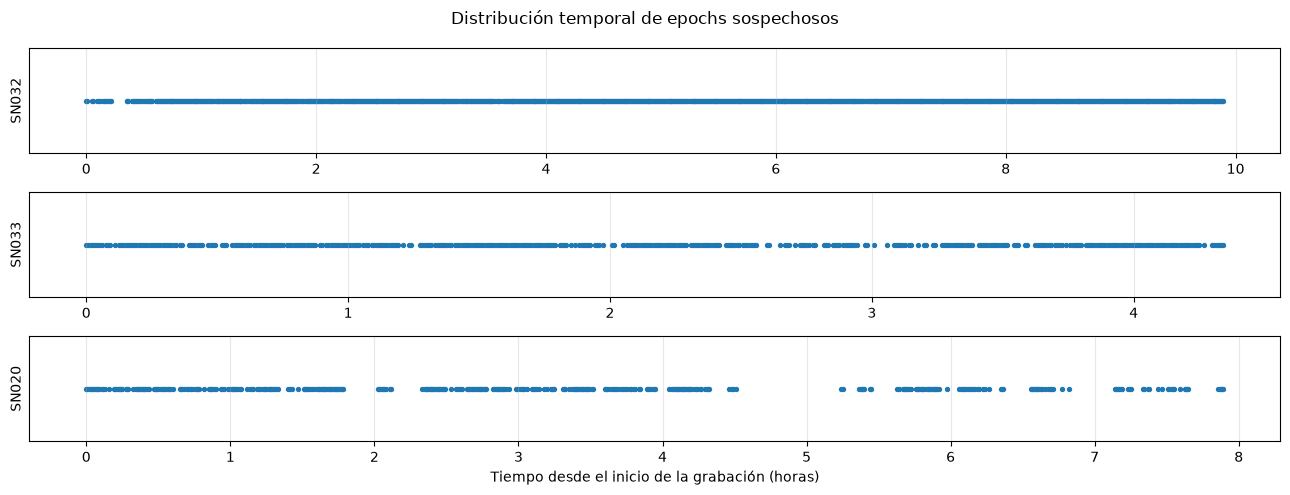

In [94]:
fig, axes = plt.subplots(
    len(SUBJECTS_TO_REVIEW),
    1,
    figsize=(13, 5),
    sharex=False
)

for ax, subject in zip(axes, SUBJECTS_TO_REVIEW):

    df_subject = df_quality_review[
        df_quality_review["subject"] == subject
    ]

    ax.scatter(
        df_subject["time_h"],
        np.ones(len(df_subject)),
        s=8
    )

    ax.set_yticks([])
    ax.set_ylabel(subject)
    ax.grid(axis="x", alpha=0.3)

axes[-1].set_xlabel("Tiempo desde el inicio de la grabación (horas)")

plt.suptitle("Distribución temporal de epochs sospechosos")
plt.tight_layout()
plt.show()

In [95]:
amplitude_summary = []

for subject in SUBJECTS_TO_REVIEW:

    edf_path = os.path.join(DATA_PATH, f"{subject}.edf")
    labels_path = os.path.join(
        LABELS_PATH,
        f"{subject}_sleepscoring.txt"
    )

    raw_subject = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose=False
    )

    subject_sfreq = raw_subject.info["sfreq"]
    epoch_samples = int(EPOCH_DURATION_S * subject_sfreq)

    eeg_channels = [
        ch for ch in raw_subject.ch_names
        if ch.startswith("EEG")
    ]

    eeg_data_uv = raw_subject.get_data(
        picks=eeg_channels
    ) * 1e6

    subject_labels = load_hypnogram(labels_path)
    max_amplitudes = []

    for _, label in subject_labels.iterrows():

        onset_s = float(label["Recording onset"])
        start = int(round(onset_s * subject_sfreq))
        end = start + epoch_samples

        if end > raw_subject.n_times:
            continue

        epoch_uv = eeg_data_uv[:, start:end]
        max_amplitudes.append(
            np.max(np.abs(epoch_uv))
        )

    max_amplitudes = np.asarray(max_amplitudes)
    suspicious = max_amplitudes[
        max_amplitudes > AMPLITUDE_THRESHOLD_UV
    ]

    amplitude_summary.append({
        "subject": subject,
        "epochs_over_500": len(suspicious),
        "median_uv": np.median(suspicious) if len(suspicious) else np.nan,
        "p95_uv": np.percentile(suspicious, 95) if len(suspicious) else np.nan,
        "p99_uv": np.percentile(suspicious, 99) if len(suspicious) else np.nan,
        "max_uv": suspicious.max() if len(suspicious) else np.nan
    })

    raw_subject.close()


df_amplitude_summary = pd.DataFrame(amplitude_summary)
display(df_amplitude_summary.round(1))

,subject,epochs_over_500,median_uv,p95_uv,p99_uv,max_uv
0,SN032,1134,800.0,800.0,800.0,800.0
1,SN033,423,800.0,800.0,800.0,800.0
2,SN020,400,800.0,800.0,800.0,800.0


In [96]:
CLIPPING_LEVEL_UV = 800

for subject in SUBJECTS_TO_REVIEW:

    edf_path = os.path.join(DATA_PATH, f"{subject}.edf")

    raw_subject = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose=False
    )

    eeg_channels = [
        ch for ch in raw_subject.ch_names
        if ch.startswith("EEG")
    ]

    eeg_data_uv = raw_subject.get_data(
        picks=eeg_channels
    ) * 1e6

    print(f"\n{subject}")

    for channel, signal_uv in zip(eeg_channels, eeg_data_uv):

        n_clipped = np.sum(
            np.isclose(
                np.abs(signal_uv),
                CLIPPING_LEVEL_UV,
                atol=0.1
            )
        )

        pct_clipped = n_clipped / len(signal_uv) * 100

        print(
            f"{channel}: "
            f"min={signal_uv.min():.1f} µV, "
            f"max={signal_uv.max():.1f} µV, "
            f"muestras en ±{CLIPPING_LEVEL_UV} µV="
            f"{n_clipped} ({pct_clipped:.2f}%)"
        )

    raw_subject.close()


SN032
EEG F4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=445630 (4.88%)
EEG C4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=510933 (5.60%)
EEG O2-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=692357 (7.59%)
EEG C3-M2: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=205117 (2.25%)

SN033
EEG F4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=86911 (2.17%)
EEG C4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=162848 (4.06%)
EEG O2-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=89475 (2.23%)
EEG C3-M2: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=84356 (2.10%)

SN020
EEG F4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=70513 (0.97%)
EEG C4-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=162198 (2.23%)
EEG O2-M1: min=-800.0 µV, max=800.0 µV, muestras en ±800 µV=84400 (1.16%)
EEG C3-M2: min=-598.6 µV, max=426.6 µV, muestras en ±800 µV=0 (0.00%)


#### Conclusión del análisis de sujetos con alta proporción de epochs sospechosos

El análisis detallado de los sujetos con mayor proporción de epochs sospechosos mostró comportamientos diferentes.

`SN032` presentó un `95.5%` de epochs marcados y `SN033` un `81.0%`. En ambos casos, los eventos de amplitud extrema afectaron simultáneamente a múltiples canales EEG y se distribuyeron a lo largo de prácticamente toda la grabación.

La inspección adicional de las amplitudes reveló que una gran cantidad de muestras alcanzan exactamente los límites de `±800 µV`, lo que es compatible con un fenómeno de **clipping o saturación de la señal**. Este comportamiento aparece de forma extensa y multicanal en `SN032` y `SN033`, por lo que se consideran registros con problemas sistemáticos de calidad y se excluyen del procesamiento posterior.

En cambio, `SN020` presentó un `42.2%` de epochs sospechosos. La mayor parte de estos eventos se concentró en los canales `F4-M1`, `C4-M1` y `O2-M1`, mientras que `C3-M2` no presentó clipping en `±800 µV`. Dado que los tres canales afectados comparten la referencia `M1`, este patrón podría estar asociado a un problema específico de esa referencia. Sin embargo, el sujeto conserva aproximadamente `4.6 horas` de señal no marcada, por lo que se mantiene en el dataset y sus epochs problemáticos se gestionarán individualmente durante la etapa de preprocessing.

Por lo tanto, la decisión final es:

- `SN032`: excluido.
- `SN033`: excluido.
- `SN020`: conservado.

---
## 12. Spectrograma EEG + hypnogram
El spectrograma muestra cómo evoluciona el contenido frecuencial en el tiempo.  
Es una de las visualizaciones más informativas en análisis de sueño.

In [97]:
# ============================================================
# Spectrograma EEG + hypnogram — primeras 2 horas
# ============================================================

SPECTROGRAM_EEG_CHANNEL = "EEG C4-M1"
SPECTROGRAM_DURATION_H = 2

raw_spec = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

spec_sfreq = raw_spec.info["sfreq"]

# Extraer solo el canal seleccionado y las primeras 2 horas
n_samples = int(
    SPECTROGRAM_DURATION_H
    * SECONDS_PER_HOUR
    * spec_sfreq
)

spec_signal_uv = raw_spec.get_data(
    picks=[SPECTROGRAM_EEG_CHANNEL],
    start=0,
    stop=min(n_samples, raw_spec.n_times)
)[0] * 1e6

# Spectrograma
f_spec, t_spec, Sxx = spectrogram(
    spec_signal_uv,
    fs=spec_sfreq,
    nperseg=int(4 * spec_sfreq),
    noverlap=int(2 * spec_sfreq),
    scaling="density"
)

# Limitar a 0.5–35 Hz
spec_freq_mask = (f_spec >= 0.5) & (f_spec <= 35)
f_plot = f_spec[spec_freq_mask]
Sxx_plot = Sxx[spec_freq_mask]

# Cargar labels correspondientes a las primeras 2 horas
spec_labels = load_hypnogram(sample_labels_path)

labels_2h = spec_labels[
    spec_labels["Recording onset"].astype(float)
    < SPECTROGRAM_DURATION_H * SECONDS_PER_HOUR
].copy()

hyp_time_h = (
    labels_2h["Recording onset"].astype(float)
    / SECONDS_PER_HOUR
)

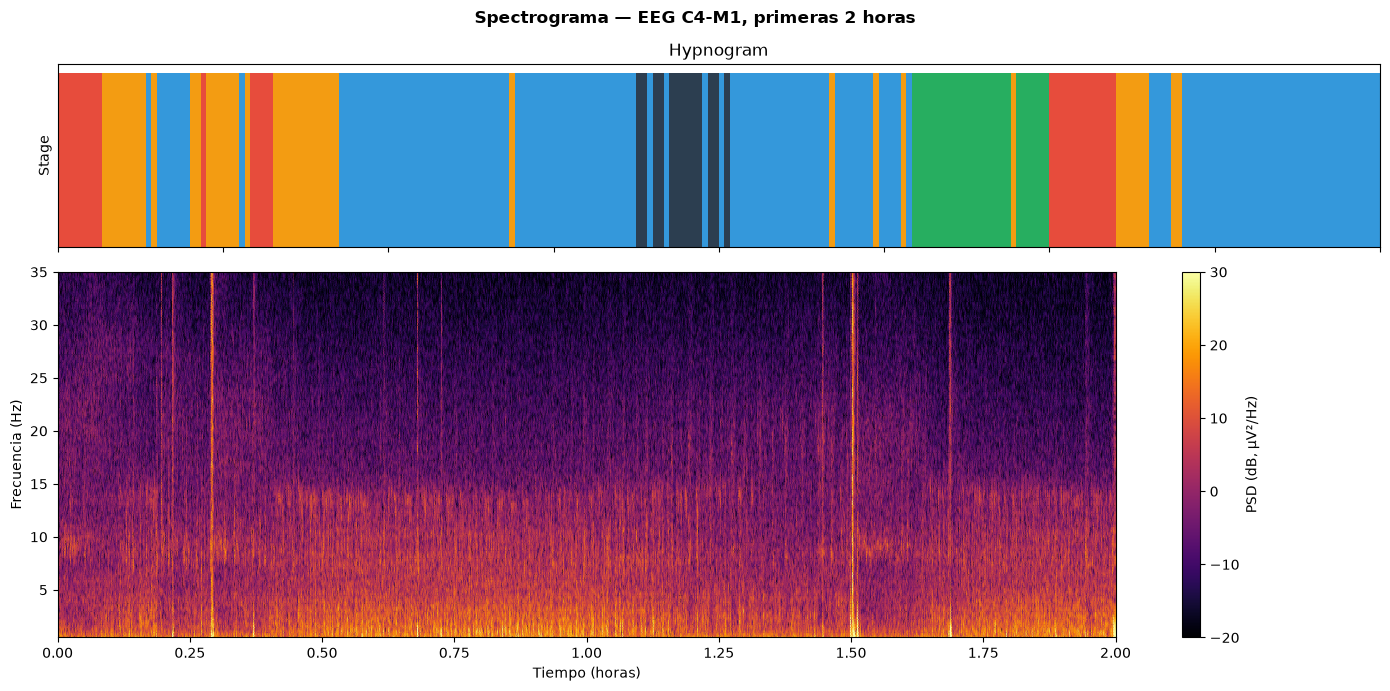

In [98]:
fig, (ax_hyp, ax_spec) = plt.subplots(
    2,
    1,
    figsize=(14, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}
)

fig.suptitle(
    f"Spectrograma — {SPECTROGRAM_EEG_CHANNEL}, "
    f"primeras {SPECTROGRAM_DURATION_H} horas",
    fontweight="bold"
)

# Hypnogram
colors = labels_2h["Annotation"].map(STAGE_COLORS).fillna("gray")

ax_hyp.bar(
    hyp_time_h,
    height=1,
    width=EPOCH_DURATION_H,
    align="edge",
    color=colors
)

ax_hyp.set_yticks([])
ax_hyp.set_ylabel("Stage")
ax_hyp.set_title("Hypnogram")

# Spectrograma
spec_time_h = t_spec / SECONDS_PER_HOUR

im = ax_spec.pcolormesh(
    spec_time_h,
    f_plot,
    10 * np.log10(Sxx_plot + 1e-30),
    cmap="inferno",
    shading="gouraud",
    vmin=-20,
    vmax=30
)

fig.colorbar(
    im,
    ax=ax_spec,
    label="PSD (dB, µV²/Hz)"
)

ax_spec.set_ylabel("Frecuencia (Hz)")
ax_spec.set_xlabel("Tiempo (horas)")
ax_spec.set_xlim(0, SPECTROGRAM_DURATION_H)
ax_spec.set_ylim(0.5, 35)

plt.tight_layout()
plt.show()

raw_spec.close()

### Spectrograma EEG y evolución temporal de las etapas de sueño

En esta sección se analizaron las primeras 2 horas del canal `EEG C4-M1`. La señal se dividió en ventanas de 4 segundos con un solapamiento del 50%, y para cada ventana se calculó la potencia espectral. El resultado se representa mediante un spectrograma:

* eje X: tiempo en horas;
* eje Y: frecuencia en Hz;
* color: potencia de la señal en dB.

En la parte superior se muestra el hypnogram correspondiente al mismo intervalo, donde cada color representa una etapa de sueño distinta.

Como observación inicial, la mayor parte de la potencia se concentra en frecuencias bajas, especialmente por debajo de 10 Hz, lo cual es esperable en señales EEG de sueño. También se observan cambios en el contenido frecuencial a medida que varían las etapas del sueño y algunos eventos verticales de mayor intensidad, que podrían corresponder a transiciones, movimientos o posibles artefactos. Esta visualización permite relacionar la evolución temporal de las etapas con cambios en la actividad espectral del EEG.


---
## 13. Resumen

In [99]:
# ============================================================
# Resumen final de la EDA
# ============================================================

EXCLUDED_SUBJECTS = [
    "SN032",
    "SN033"
]

n_original_subjects = len(edf_signals)
n_subjects_with_labels = n_original_subjects - len(missing_labels)
n_retained_subjects = n_original_subjects - len(EXCLUDED_SUBJECTS)

print("=" * 60)
print("RESUMEN DEL ANÁLISIS EXPLORATORIO")
print("=" * 60)

print(f"Sujetos originales:             {n_original_subjects}")
print(f"Sujetos con labels:              {n_subjects_with_labels}")
print(f"Conjuntos de canales distintos:  {unique_channel_sets}")
print(f"Sampling rates encontrados:      {df_info['sfreq'].unique()}")

print(
    f"Labels con separación regular:   "
    f"{df_label_timing['regular_30s'].sum()} / "
    f"{len(df_label_timing)}"
)

print(
    f"Labels que comienzan en t=0:     "
    f"{df_label_timing['starts_at_zero'].sum()} / "
    f"{len(df_label_timing)}"
)

print()
print(f"Sujetos excluidos por calidad:   {EXCLUDED_SUBJECTS}")
print(f"Sujetos retenidos:               {n_retained_subjects}")

print()
print("Siguiente etapa:")
print(
    "02_preprocessing.ipynb → "
    "QC, alineación temporal, resampling, filtrado, "
    "segmentación, normalización y guardado."
)

RESUMEN DEL ANÁLISIS EXPLORATORIO
Sujetos originales:             151
Sujetos con labels:              151
Conjuntos de canales distintos:  1
Sampling rates encontrados:      [256.]
Labels con separación regular:   151 / 151
Labels que comienzan en t=0:     151 / 151

Sujetos excluidos por calidad:   ['SN032', 'SN033']
Sujetos retenidos:               149

Siguiente etapa:
02_preprocessing.ipynb → QC, alineación temporal, resampling, filtrado, segmentación, normalización y guardado.
